# Procrustes optimisation

A finished circuit can be refit gate by gate against the target by Procrustes sweeps, without changing the gate count or the connectivity. This notebook refits ASPIRE and MPD circuits with a stopping rule, compares warm-start Procrustes selection with plain ASPIRE selection, and refines a small ground-state circuit by the energy. Blue is the MPD and orange is ASPIRE.

In [1]:
using Pkg; Pkg.activate(@__DIR__)

In [2]:
using ASPIRE, MPSCircuits, ITensors, ITensorMPS, LinearAlgebra, Random, Plots, Printf
ITensors.disable_warn_order()

set_max_bond_dim!(64)
default(framestyle = :box, linewidth = 2, markersize = 5, guidefontsize = 10, titlefontsize = 10,
        left_margin = 4Plots.mm, bottom_margin = 4Plots.mm)
const BLUE, ORANGE, GREEN, GREY = "#1f77b4", "#ff7f0e", "#2ca02c", "#555555"
two_qubit_gates(circuit) = count(g -> length(g.site_numbers) == 2, circuit)

two_qubit_gates (generic function with 1 method)

Refitting with the stopping rule. `optimize_to_floor` repeats sweeps until each of the last three measurement intervals lowers the infidelity by less than a fraction $10^{-7}$ of its value, or a sweep cap is reached. Both circuits have 26 two-qubit gates (two MPD layers) on the 14-site targets, and the infidelity is measured against the fixed state $|0\rangle^{\otimes N}$. Runs that reach the cap are marked as capped, and their floor is an upper bound.

In [3]:
BUDGET, LAYERS = 26, 2
SWEEP_CAP = 300

aspire_config(gmax) = ASPIREConfig(threshold = 0.0, relative_threshold = 0.0, max_depth = 30, max_gates = gmax,
                                   batch_mode = :matching, shortlist = 32, cost_normalised = false)

small = ["TFIM 7x2, h = 2" => tfim_snake_state(7, 2; J = 1.0, h = 2.0, nsweeps = 8, maxdim = [10, 20, 40, 64], rng = MersenneTwister(1)),
         "Heisenberg 7x2" => heisenberg_snake_state(7, 2; nsweeps = 8, maxdim = [10, 20, 40, 64], rng = MersenneTwister(1))]

function floors(psi)
    asp = prep_circuit_from_gate_log(aspire(psi; config = aspire_config(BUDGET)).gate_log, siteinds(psi))
    mpd = mpd_circuit(psi, LAYERS)
    return map(["ASPIRE" => asp, "MPD" => mpd]) do (label, circuit)
        out = optimize_to_floor(psi, circuit; rtol = 1e-7, patience = 3, cap = SWEEP_CAP, max_bond_dim = 64)
        label => (out = out, gates = two_qubit_gates(circuit))
    end
end

runs1 = [name => floors(psi) for (name, psi) in small]
for (name, runs) in runs1, (label, r) in runs
    println(rpad(name, 18), rpad(label, 8), "gates = ", r.gates, "   start = ", round(r.out.infid0, sigdigits = 3),
            "   floor = ", round(r.out.floor, sigdigits = 3), "   sweeps = ", r.out.sweeps, "   capped = ", r.out.capped)
end

TFIM 7x2, h = 2   ASPIRE  gates = 26   start = 0.000175   floor = 0.000145   sweeps = 300   capped = true
TFIM 7x2, h = 2   MPD     gates = 26   start = 0.0106   floor = 0.0078   sweeps = 110   capped = false
Heisenberg 7x2    ASPIRE  gates = 26   start = 0.2   floor = 0.163   sweeps = 300   capped = true
Heisenberg 7x2    MPD     gates = 26   start = 0.41   floor = 0.257   sweeps = 300   capped = true


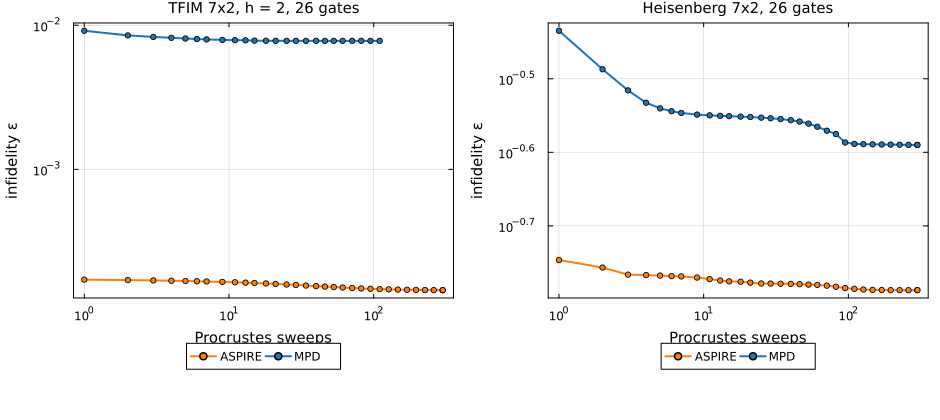

In [4]:
panels = map(runs1) do (name, runs)
    p = plot(; xscale = :log10, yscale = :log10, xlabel = "Procrustes sweeps", ylabel = "infidelity ε",
             title = "$name, $BUDGET gates", legend = :outerbottom, legend_columns = 2)
    for ((label, r), color) in zip(runs, (ORANGE, BLUE))
        plot!(p, r.out.trace_at[2:end], r.out.trace[2:end]; color = color, marker = :circle, markersize = 3, label = label)
    end
    p
end
plot(panels...; layout = (1, 2), size = (940, 420))

Warm-start selection. The first $k$ layers are chosen by removable mutual information and later layers by the largest overlap gain with $|0\rangle^{\otimes N}$ that one gate can reach. Every layer is followed by two Procrustes sweeps of the whole circuit, with at most four gates per layer, up to 33 gates. The reference, labelled plain, never switches.

In [5]:
heis = heisenberg_snake_state(4, 3; nsweeps = 8, maxdim = [8, 16, 32], rng = MersenneTwister(1))
tfim = tfim_snake_state(3, 4; J = 1.0, h = 1.0, nsweeps = 8, maxdim = [8, 16, 32], rng = MersenneTwister(1))
targets = ["Heisenberg 4x3" => heis, "TFIM 3x4, h = 1" => tfim]

WS_BUDGET, WS_SWEEPS, WS_BATCH = 33, 2, 4
ks = [0, 1, 2, 5]
PLAIN = 1000

warm_run(psi, k) = protocol_arb_iter_oall(psi; budget = WS_BUDGET, sweeps = WS_SWEEPS, proposals = switch_schedule(k),
                                          max_batch = WS_BATCH, max_bond_dim = 64)

warm = Dict{String,Any}()
for (name, psi) in targets
    warm[name] = Dict(k => warm_run(psi, k) for k in [ks; PLAIN])
end

for (name, _) in targets
    plain = warm[name][PLAIN]
    println(name, ": plain ASPIRE reaches ", plain.gates[end], " gates, final ε = ", round(plain.infid[end], sigdigits = 3))
    for k in ks
        r = warm[name][k]
        if isempty(r.gates)
            println("   k = $k: no gate emitted")
        else
            println("   k = $k: ", r.gates[end], " gates, final ε = ", round(r.infid[end], sigdigits = 3),
                    "   ratio plain / warm = ", round(plain.infid[end] / r.infid[end], digits = 2))
        end
    end
end

Heisenberg 4x3: plain ASPIRE reaches 33 gates, final ε = 0.128
   k = 0: 33 gates, final ε = 0.106   ratio plain / warm = 1.21
   k = 1: 33 gates, final ε = 0.0717   ratio plain / warm = 1.78
   k = 2: 33 gates, final ε = 0.123   ratio plain / warm = 1.04
   k = 5: 33 gates, final ε = 0.119   ratio plain / warm = 1.07
TFIM 3x4, h = 1: plain ASPIRE reaches 33 gates, final ε = 0.0908
   k = 0: 33 gates, final ε = 0.00702   ratio plain / warm = 12.94
   k = 1: 33 gates, final ε = 0.00712   ratio plain / warm = 12.76
   k = 2: 33 gates, final ε = 0.0136   ratio plain / warm = 6.69
   k = 5: 33 gates, final ε = 0.0141   ratio plain / warm = 6.43


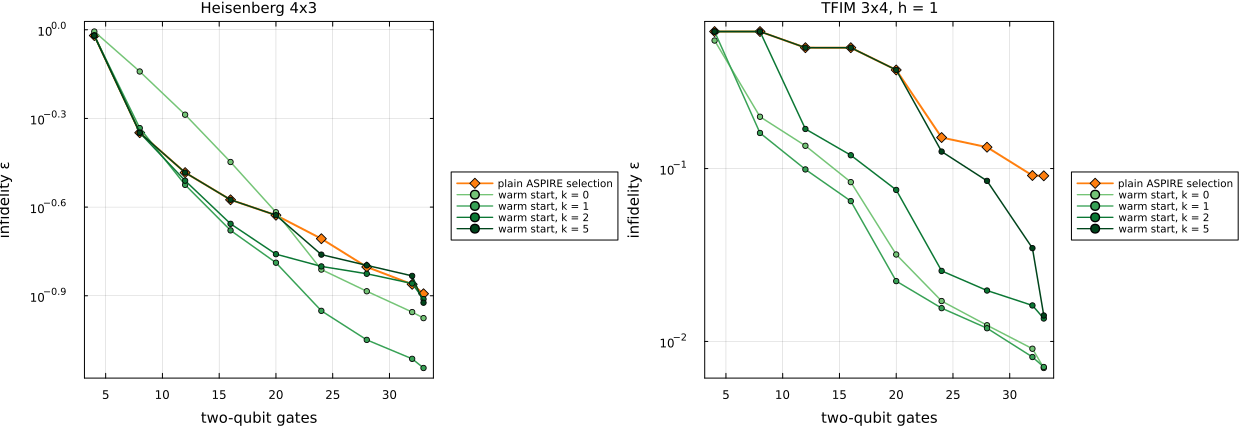

In [6]:
panels = map(targets) do (name, psi)
    p = plot(; yscale = :log10, xlabel = "two-qubit gates", ylabel = "infidelity ε", title = name, legend = :outerright,
             legendfontsize = 7)
    plain = warm[name][PLAIN]
    plot!(p, plain.gates, plain.infid; color = ORANGE, marker = :diamond, label = "plain ASPIRE selection")
    shades = palette(:Greens, length(ks) + 3)[4:end]
    for (k, c) in zip(ks, shades)
        r = warm[name][k]
        isempty(r.gates) && continue
        plot!(p, r.gates, r.infid; color = c, marker = :circle, markersize = 3, linewidth = 1.5, label = "warm start, k = $k")
    end
    p
end
plot(panels...; layout = (1, 2), size = (1250, 440), bottom_margin = 8Plots.mm)

Energy refinement. For the 8-site transverse-field Ising chain at $h=0.5$, a source MPS of bond dimension 2 is compiled into a 21-gate circuit on ASPIRE supports by 10 fidelity sweeps. The circuit is then continued either by 12 energy sweeps or, as a control, by 12 more fidelity sweeps. The exact ground state comes from dense diagonalisation.

In [7]:
set_cutoff!(1e-12)
N, h = 8, 0.5
sites, H = tfim_setup(N; h=h)
psi_exact, E0 = ed_ground_state(H)
psi_src, E_src = tfim_dmrg(H, sites; nsweeps=1, maxdim=[2], cutoff=1e-14, rng=MersenneTwister(1))

eps_of(a, b) = 1 - abs(inner(a, b))
src_err = (E_src - E0) / N
src_exact_eps = eps_of(psi_src, psi_exact)
@printf("E0 = %.6f, gap = %.4f\n", E0, ed_ground_gap(H))
@printf("source: chi = %d, (E - E0)/N = %.3e, epsilon to exact = %.3e\n",
    maxlinkdim(psi_src), src_err, src_exact_eps)

config = ASPIREConfig(threshold=0.0, relative_threshold=0.0, max_gates=21, max_depth=40,
    batch_mode=:blossom, cost_normalised=false, accept_only=false, min_objective_gain=-1e6)
run = aspire(psi_src; config=config)
aspire_supports = reverse([(g.i, g.j) for g in run.gate_log])
identity_circuit(supports) = MPSCircuits.UnitaryGate[
    MPSCircuits.UnitaryGate(two_qubit_gate(Matrix{ComplexF64}(I, 4, 4), sites[i], sites[j]))
    for (i, j) in supports]
println("gates: ", length(aspire_supports), ", long-range gates (span > 1): ",
    count(p -> p[2] - p[1] > 1, aspire_supports))

E0 = -2.459488, gap = 0.0923
source: chi = 2, (E - E0)/N = 1.348e-03, epsilon to exact = 3.236e-02
gates: 21, long-range gates (span > 1): 14


In [8]:
zero_state = MPS(sites, fill("0", N))
prepared(C) = normalize!(MPSCircuits.apply_circuit(C, zero_state; cutoff=1e-12, maxdim=64))
function record(C)
    st = prepared(C)
    return (e=(energy(st, H) - E0) / N, src=eps_of(st, psi_src), exact=eps_of(st, psi_exact))
end

function protocol(supports; fid_sweeps=10, extra_sweeps=12)
    C = identity_circuit(supports)
    fid = [record(C)]
    for _ in 1:fid_sweeps
        oall_sweep!(psi_src, C; sweeps=1)
        push!(fid, record(C))
    end
    energy_arm = [fid[end]]; Ce = deepcopy(C)
    for _ in 1:extra_sweeps
        Ce = energy_mps_coordinate_refine(H, Ce; n_sweeps=1, cutoff=1e-12, maxdim=64).circuit
        push!(energy_arm, record(Ce))
    end
    fid_arm = [fid[end]]; Cf = deepcopy(C)
    for _ in 1:extra_sweeps
        oall_sweep!(psi_src, Cf; sweeps=1)
        push!(fid_arm, record(Cf))
    end
    return (fid=fid, energy=energy_arm, fidonly=fid_arm)
end

res = protocol(aspire_supports)
last_f, last_e, last_c = res.fid[end], res.energy[end], res.fidonly[end]
@printf("%-24s %12s %12s %12s\n", "state", "(E-E0)/N", "eps source", "eps exact")
@printf("%-24s %12.3e %12.3e %12.3e\n", "source MPS", src_err, 0.0, src_exact_eps)
@printf("%-24s %12.3e %12.3e %12.3e\n", "fidelity sweeps (10)", last_f.e, last_f.src, last_f.exact)
@printf("%-24s %12.3e %12.3e %12.3e\n", "+ 12 energy sweeps", last_e.e, last_e.src, last_e.exact)
@printf("%-24s %12.3e %12.3e %12.3e\n", "+ 12 fidelity sweeps", last_c.e, last_c.src, last_c.exact)

state                        (E-E0)/N   eps source    eps exact
source MPS                  1.348e-03    0.000e+00    3.236e-02
fidelity sweeps (10)        1.494e-03    3.001e-04    3.278e-02
+ 12 energy sweeps          1.873e-04    1.969e-02    2.404e-03
+ 12 fidelity sweeps        1.401e-03    1.145e-04    3.252e-02


Solid curves: fidelity sweeps, then energy sweeps from the vertical line. Dashed curves: fidelity sweeps continued. The dotted line is the source MPS.

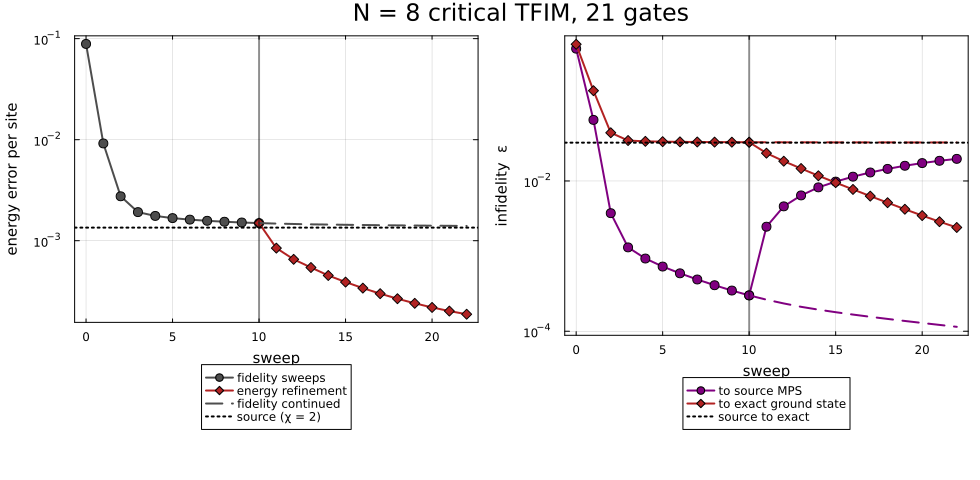

In [9]:
sw = length(res.fid) - 1
xf = 0:sw
xe = sw:(sw + length(res.energy) - 1)

pa = plot(ylabel="energy error per site", yscale=:log10, xlabel="sweep", legend=:outerbottom)
plot!(pa, xf, [r.e for r in res.fid]; color=:gray30, marker=:circle, label="fidelity sweeps")
plot!(pa, xe, [r.e for r in res.energy]; color=:firebrick, marker=:diamond, label="energy refinement")
plot!(pa, xe, [r.e for r in res.fidonly]; color=:gray30, linestyle=:dash, label="fidelity continued")
hline!(pa, [src_err]; color=:black, linestyle=:dot, label="source (χ = 2)")
vline!(pa, [sw]; color=:black, alpha=0.4, label="")

pb = plot(ylabel="infidelity  ε", yscale=:log10, xlabel="sweep", legend=:outerbottom)
plot!(pb, xf, [r.src for r in res.fid]; color=:purple, marker=:circle, label="to source MPS")
plot!(pb, xe, [r.src for r in res.energy]; color=:purple, marker=:circle, label="")
plot!(pb, xe, [r.src for r in res.fidonly]; color=:purple, linestyle=:dash, label="")
plot!(pb, xf, [r.exact for r in res.fid]; color=:firebrick, marker=:diamond, label="to exact ground state")
plot!(pb, xe, [r.exact for r in res.energy]; color=:firebrick, marker=:diamond, label="")
plot!(pb, xe, [r.exact for r in res.fidonly]; color=:firebrick, linestyle=:dash, label="")
hline!(pb, [src_exact_eps]; color=:black, linestyle=:dot, label="source to exact")
vline!(pb, [sw]; color=:black, alpha=0.4, label="")
plot(pa, pb; layout=(1, 2), size=(980, 480), plot_title="N = 8 critical TFIM, 21 gates")